<a href="https://colab.research.google.com/github/Nicolas-Bernal/Simulacion-Estadistica/blob/main/MARKOV%20CHAIN%20MONTE%20CARLO/Metropolis%20Hasting/METROPOLIS%E2%80%93HASTINGS_ALGORITHM.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

7.1, 7.2,7.6, 7.7

# Algunas Simulaciones Metropolis Hasting usando el kernel de R

---




## 7.1.

### *El objetivo de este problema es investigar el papel de la distribución propuesta en un algoritmo de Metropolis–Hastings diseñado para simular a partir de la distribución a posteriori de un parámetro $\delta$. En la parte (a), se le pide que simule datos de una distribución con $\delta$ conocido. Para las partes (b)–(d), asuma que $\delta$ es desconocido con una distribución a priori $\text{Unif}(0,1)$ para $\delta$. Para las partes (b)–(d), proporcione un gráfico adecuado y una tabla que resuma la salida del algoritmo. Para facilitar las comparaciones, utilice el mismo número de iteraciones, semilla aleatoria, valores iniciales y periodo de calentamiento (burn-in) para todas las implementaciones del algoritmo*





* *a. Simule 200 realizaciones de la distribución de mezcla en la Ecuación (7.6) con $\delta = 0.7$. Dibuje un histograma de estos datos*



* *b. Implemente un procedimiento MCMC de cadena de independencia para simular a partir de la distribución a posteriori de $\delta$, utilizando sus datos de la parte (a).*

* *c. Implemente una cadena de caminata aleatoria con $\delta = \delta^{(t)} + \varepsilon$ donde $\varepsilon \sim \text{Unif}(-1,1)$.*

* *d. Reparametrize el problema definiendo $U = \log\{\delta / (1 - \delta)\}$ y $U = u^{(t)} + \varepsilon$. Implemente una cadena de caminata aleatoria en el espacio $U$ como en la Ecuación (7.8).*

* *e. Compare las estimaciones y el comportamiento de convergencia de los tres algoritmos.*

### $a)$

*Tomando :*
$$X \sim \delta \, \mathcal{N}(7, \, 0.5^2) + (1 - \delta) \, \mathcal{N}(10, \, 0.5^2)$$

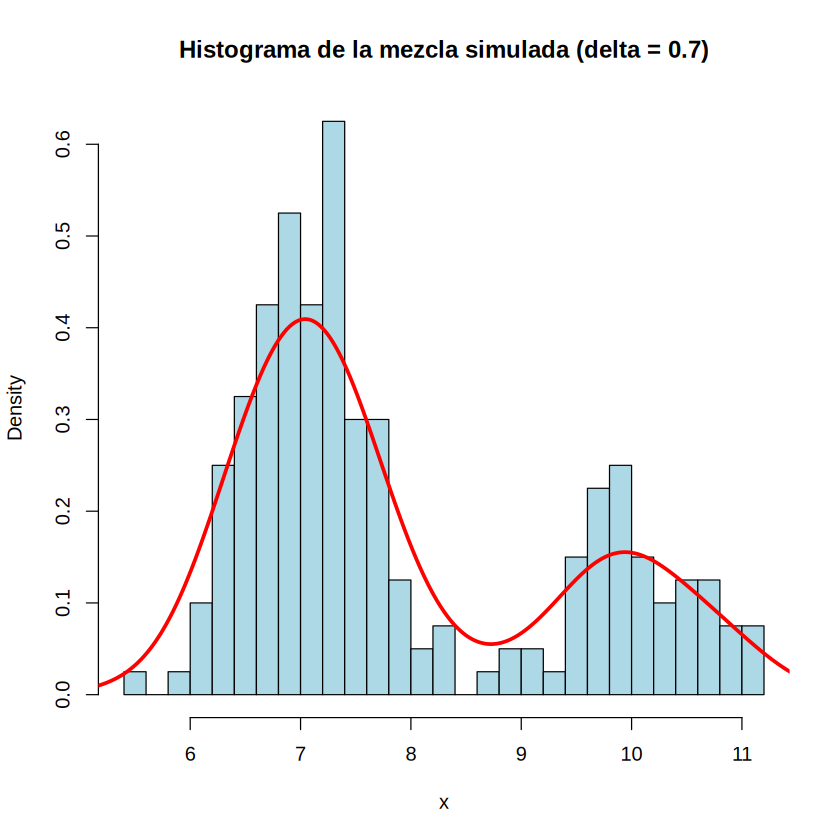

In [93]:
set.seed(777)

n = 200
Delta1 = 0.7

u = runif(n)

componentes = ifelse(u < delta,1,2)
x = numeric(n)

x[componentes == 1] = rnorm(sum(componentes == 1),mean = 7,sd = 0.5)
x[componentes == 2] = rnorm(sum(componentes == 2),mean = 10,sd = 0.5)

hist(x,breaks = 25,probability = TRUE,main = "Histograma de la mezcla simulada (delta = 0.7)",xlab = "x",col = "lightblue",border = "black")
lines(density(x),col = 'red',lwd = 3)

### $b)$

*implementaremos un algoritmo MCMC de cadena de independencia (Independence Chain).*

1. Propuesta
En cada paso $t$, proponemos un nuevo $\delta^* \sim \text{Unif}(0,1)$.

---

2. Log-Verosimilitud
Para evitar problemas de precisión numérica (*underflow*) al multiplicar $200$ probabilidades pequeñas, calculamos la log-verosimilitud:

$$\log L(\delta \mid x) = \sum_{i=1}^{n} \log \left[ \delta \cdot f_1(x_i) + (1-\delta) \cdot f_2(x_i) \right]$$

donde:
* $f_1(x_i) = \text{dnorm}(x_i, 7, 0.5)$
* $f_2(x_i) = \text{dnorm}(x_i, 10, 0.5)$

---

3. Probabilidad de Aceptación ($\alpha$)
Dado que la propuesta y la distribución a priori son simétricas y uniformes en $(0,1)$, el cociente de aceptación se reduce a la razón de verosimilitudes:

$$\alpha = \min\left(1, \; \frac{L(\delta^* \mid x)}{L(\delta^{(t)} \mid x)}\right) \implies \log \alpha = \min\left(0, \; \log L(\delta^* \mid x) - \log L(\delta^{(t)} \mid x)\right)$$

---

4. Criterio de Aceptación
Si $\log(u) \le \log \alpha$ con $u \sim \text{Unif}(0,1)$, aceptamos $\delta^{(t+1)} = \delta^*$. De lo contrario, nos quedamos con $\delta^{(t+1)} = \delta^{(t)}$.

In [94]:
set.seed(777)

# log

log_ind = function(delta, datos) {
  if (delta <= 0 || delta >= 1) return(-Inf)

  f1 = dnorm(datos, mean = 7, sd = 0.5)

  f2 = dnorm(datos, mean = 10, sd = 0.5)

  sum(log(delta * f1 + (1 - delta) * f2))
}

# Variables

N = 10000
burn_in = 1000
delta_init = 0.5

cadena = numeric(N)
cadena[1] = delta_init
aceptados = 0


In [121]:
# Algoritmo MCMC

set.seed(777)

for(t in 1:(N-1)){
  delta_prop = runif(1,min = 0,max = 1)
  log_alpha = log_ind(delta_prop,x) - log_ind(cadena[t],x)

  if(log(runif(1)) < log_alpha){
    cadena[t + 1] = delta_prop
    aceptados = aceptados + 1
  } else {
    cadena[t + 1] = cadena[t]
  }
}

# burn-in

cadena_burn = cadena[(burn_in + 1):N]
tasa_aceptacion = aceptados / (N-1)
tasa_aceptacion

[1] 2.075008

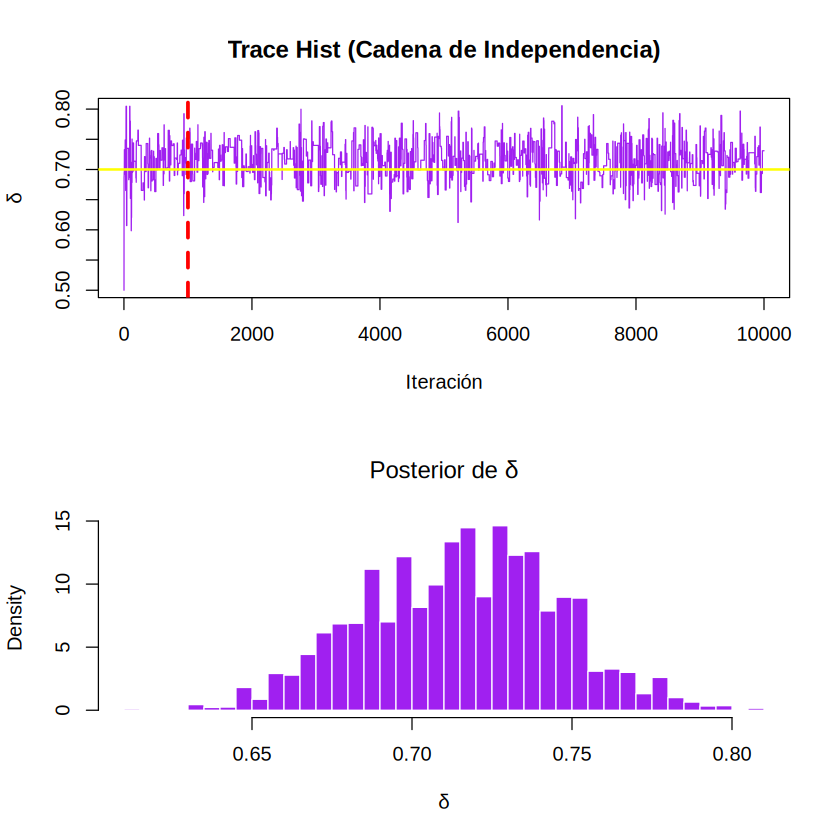

In [152]:
# Graficos

par(mfrow = c(2,1))

plot(cadena,type = "l",col = "purple",main = "Trace Hist (Cadena de Independencia)",xlab = "Iteración", ylab = expression(delta))
abline(v = burn_in,col = "red",lwd = 3, lty = 2)
abline(h = Delta1, col = "yellow", lwd = 2)

hist(cadena_burn, breaks = 30, probability = TRUE,
     col = "purple", border = "white",
     main = expression(paste("Posterior de ", delta)),
     xlab = expression(delta))

In [153]:
resumen_b <- data.frame(
  Algoritmo = "Cadena de Independencia",
  Media_Posterior = mean(cadena_b_post),
  Mediana_Posterior = median(cadena_b_post),
  Desv_Estd = sd(cadena_b_post),
  IC_95_Inf = quantile(cadena_b_post, 0.025),
  IC_95_Sup = quantile(cadena_b_post, 0.975),
  Tasa_Aceptacion = tasa_aceptacion_b
)

print(resumen_b)

                   Algoritmo Media_Posterior Mediana_Posterior  Desv_Estd
2.5% Cadena de Independencia       0.7212101         0.7245949 0.03185512
     IC_95_Inf IC_95_Sup Tasa_Aceptacion
2.5% 0.6545406 0.7801598      0.09850985


### $c)$